In [1]:
import ast
import json
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import wfdb
from scipy.signal import butter, sosfiltfilt, welch

In [2]:
PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DATABASE_FILE = "ptbxl_database.csv"
STATEMENTS_FILE = "scp_statements.csv"
SIGNALS_FILE = "cohort_signals_100hz.npy"
RECORDS_FILE = "cohort_records.parquet"
REPORT_FILE = "preprocessing_report.json"
DATASET_VERSION = "1.0.3"
SAMPLING_RATE = 100
SIGNAL_LENGTH = 1000
FILENAME_COLUMN = "filename_lr"
LEAD_NAMES = ("I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6")
LEAD_GRID = (6, 2)
SUPERCLASSES = ("NORM", "MI", "STTC", "CD", "HYP")
CONFLICTING_WITH_NORM = ("MI", "STTC", "HYP")
LIKELIHOOD_THRESHOLD = 0
MAX_PLAUSIBLE_AGE = 120
CAPPED_AGE = 90
MIN_ADULT_AGE = 18
EXCLUSION_REASONS = ("no_superclass", "under_adult_age", "integrity_issue")
INTEGRITY_COLUMNS = ("non_finite", "flat_leads", "clipped_leads")
BLOCKING_INTEGRITY_COLUMNS = ("non_finite", "flat_leads")
INTEGRITY_BATCH_SIZE = 2048
FLATLINE_STD_THRESHOLD = 0.01
CLIPPING_FRACTION_THRESHOLD = 0.02
SIGNAL_QUALITY_COLUMNS = ("static_noise", "burst_noise", "baseline_drift", "electrodes_problems", "extra_beats", "pacemaker")
RECORD_IDENTITY_COLUMNS = ("patient_id", "group_id", "age", "sex")
RECORD_CONTEXT_COLUMNS = ("device", "site", "validated_by_human", "strat_fold")
DUPLICATE_DOWNSAMPLE_FACTOR = 4
DUPLICATE_CORRELATION_THRESHOLD = 0.99
DUPLICATE_BATCH_SIZE = 2048
FILTER_ORDER = 4
HIGHPASS_CUTOFF = 0.5
BANDPASS_CUTOFFS = (0.5, 40.0)
FILTER_VARIANTS = ("raw", "highpass", "bandpass")
SPECTRUM_SAMPLE_SIZE = 500
SPECTRUM_SEGMENT_LENGTH = 1000
OFFICIAL_TEST_FOLDS = (9, 10)
OFFICIAL_FOLD_GROUPS = ("folds 1-8", "folds 9-10")
RANDOM_SEED = 42
BASE_FIGURE_SIZE = (12, 5)
WIDE_FIGURE_SIZE = (18, 6)
SQUARE_FIGURE_SIZE = (9, 8)
LEAD_FIGURE_SIZE = (16, 14)
COMPARISON_ROW_HEIGHT = 2.0
FIGURE_DPI = 110
PRIMARY_COLOR = "#2E5E8C"
SECONDARY_COLOR = "#E07A5F"
NEUTRAL_COLOR = "#9AA5B1"
SEQUENTIAL_CMAP = "Blues"
SUPERCLASS_COLORS = {"NORM": "#4C9F70", "MI": "#D1495B", "STTC": "#EDAE49", "CD": "#00798C", "HYP": "#7B5EA7"}
FILTER_COLORS = {"raw": NEUTRAL_COLOR, "highpass": PRIMARY_COLOR, "bandpass": SECONDARY_COLOR}

In [3]:
class PlotTheme:
    @staticmethod
    def apply():
        sns.set_theme(style="whitegrid", context="notebook")
        plt.rcParams.update({
            "figure.figsize": BASE_FIGURE_SIZE,
            "figure.dpi": FIGURE_DPI,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.labelsize": 11,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "legend.frameon": False
        })

    @staticmethod
    def class_colors(labels):
        return [SUPERCLASS_COLORS.get(label, NEUTRAL_COLOR) for label in labels]

    @staticmethod
    def figure(nrows=1, ncols=1, size=BASE_FIGURE_SIZE, sharex=False, sharey=False):
        return plt.subplots(nrows, ncols, figsize=size, sharex=sharex, sharey=sharey, constrained_layout=True)

    @staticmethod
    def decorate(ax, title, xlabel=None, ylabel=None):
        ax.set_title(title)
        ax.set_xlabel(xlabel or "")
        ax.set_ylabel(ylabel or "")

PlotTheme.apply()

In [4]:
class MetadataRepository:
    def __init__(self, raw_dir):
        self.raw_dir = raw_dir

    def load_database(self):
        database = pd.read_csv(self.raw_dir / DATABASE_FILE, index_col="ecg_id")
        database["scp_codes"] = database["scp_codes"].apply(ast.literal_eval)
        database["device"] = database["device"].str.split().str.join(" ")
        return database

    def load_statements(self):
        statements = pd.read_csv(self.raw_dir / STATEMENTS_FILE, index_col=0)
        statements.index.name = "statement"
        return statements

class LabelHierarchy:
    def __init__(self, statements):
        diagnostic = statements[statements["diagnostic"] == 1]
        self.superclass_of = diagnostic["diagnostic_class"].to_dict()

    @staticmethod
    def confident_statements(codes, threshold=0):
        return [code for code, likelihood in codes.items() if likelihood >= threshold]

    def superclasses(self, codes, threshold=0):
        return sorted({self.superclass_of[code] for code in self.confident_statements(codes, threshold) if code in self.superclass_of})

    def superclass_likelihoods(self, codes):
        strongest = {}
        for code, likelihood in codes.items():
            if code in self.superclass_of:
                superclass = self.superclass_of[code]
                strongest[superclass] = max(strongest.get(superclass, likelihood), likelihood)
        return strongest

    def statements_of(self, codes, superclass):
        return [code for code in codes if self.superclass_of.get(code) == superclass]

class LabelMatrix:
    @staticmethod
    def from_lists(label_lists, classes):
        return pd.DataFrame({label: label_lists.apply(lambda labels: label in labels) for label in classes}).astype(int)

In [5]:
class SignalRepository:
    def __init__(self, raw_dir, database):
        self.raw_dir = raw_dir
        self.database = database

    def load(self, ecg_id):
        signal, _ = wfdb.rdsamp(str(self.raw_dir / self.database.at[ecg_id, FILENAME_COLUMN]))
        return signal.T.astype(np.float32)

    def load_all(self):
        bank = np.empty((len(self.database), len(LEAD_NAMES), SIGNAL_LENGTH), dtype=np.float32)
        for row, ecg_id in enumerate(self.database.index):
            bank[row] = self.load(ecg_id)
        return bank

class SignalInspector:
    @staticmethod
    def time_axis(length, rate):
        return np.arange(length) / rate

    @staticmethod
    def batch_integrity(batch):
        at_extremes = (batch == batch.max(axis=2, keepdims=True)) | (batch == batch.min(axis=2, keepdims=True))
        return np.stack(
            [
                (~np.isfinite(batch)).sum(axis=(1, 2)),
                (batch.std(axis=2) < FLATLINE_STD_THRESHOLD).sum(axis=1),
                (at_extremes.mean(axis=2) > CLIPPING_FRACTION_THRESHOLD).sum(axis=1)
            ],
            axis=1
        )

    @staticmethod
    def integrity_report(bank, index):
        batches = [SignalInspector.batch_integrity(bank[start:start + INTEGRITY_BATCH_SIZE]) for start in range(0, len(bank), INTEGRITY_BATCH_SIZE)]
        return pd.DataFrame(np.concatenate(batches), index=index, columns=list(INTEGRITY_COLUMNS))

    @staticmethod
    def mean_power(batch, rate):
        frequencies, power = welch(batch, fs=rate, nperseg=SPECTRUM_SEGMENT_LENGTH, axis=-1)
        return pd.Series(power.mean(axis=(0, 1)), index=frequencies)

class SignalFilter:
    def __init__(self, rate):
        self.sections = {
            "highpass": butter(FILTER_ORDER, HIGHPASS_CUTOFF, btype="highpass", fs=rate, output="sos"),
            "bandpass": butter(FILTER_ORDER, BANDPASS_CUTOFFS, btype="bandpass", fs=rate, output="sos")
        }

    def apply(self, signals, variant):
        if variant == "raw":
            return signals
        return sosfiltfilt(self.sections[variant], signals, axis=-1).astype(np.float32)

    def variants(self, signal):
        return {variant: self.apply(signal, variant) for variant in FILTER_VARIANTS}

    def most_affected_lead(self, signal, variant):
        return int(np.argmax((signal - self.apply(signal, variant)).std(axis=-1)))

In [6]:
class CohortFilter:
    def __init__(self, database, integrity):
        self.masks = pd.DataFrame({
            "no_superclass": database["superclasses"].str.len().eq(0),
            "under_adult_age": database["age"].lt(MIN_ADULT_AGE),
            "integrity_issue": integrity[list(BLOCKING_INTEGRITY_COLUMNS)].gt(0).any(axis=1)
        })[list(EXCLUSION_REASONS)]

    @property
    def excluded(self):
        return self.masks.any(axis=1)

    def reason_combinations(self):
        excluded_masks = self.masks[self.excluded]
        return excluded_masks.apply(lambda row: " + ".join(row.index[row]), axis=1).value_counts()

    def excluded_ids(self):
        return {reason: self.masks.index[self.masks[reason]].tolist() for reason in self.masks.columns}

class ExampleSelector:
    def __init__(self, flags, rng):
        self.flags = flags
        self.rng = rng

    def flagged_row(self, column):
        return int(self.rng.choice(np.flatnonzero(self.flags[column].to_numpy())))

class NearDuplicateFinder:
    def __init__(self):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def embed(self, bank):
        coarse = bank.reshape(len(bank), bank.shape[1], -1, DUPLICATE_DOWNSAMPLE_FACTOR).mean(axis=3)
        centered = coarse - coarse.mean(axis=2, keepdims=True)
        standardized = centered / (centered.std(axis=2, keepdims=True) + 1e-8)
        return torch.nn.functional.normalize(torch.from_numpy(standardized.reshape(len(bank), -1)).to(self.device), dim=1)

    def scan(self, bank, ecg_ids):
        embeddings = self.embed(bank)
        nearest, pairs = [], []
        for start in range(0, len(embeddings), DUPLICATE_BATCH_SIZE):
            similarity = embeddings[start:start + DUPLICATE_BATCH_SIZE] @ embeddings.T
            rows = torch.arange(len(similarity), device=self.device)
            similarity[rows, rows + start] = -1.0
            nearest.append(similarity.max(dim=1).values.cpu())
            first, second = torch.nonzero(torch.triu(similarity > DUPLICATE_CORRELATION_THRESHOLD, diagonal=start + 1), as_tuple=True)
            pairs.append(pd.DataFrame({
                "ecg_id_a": ecg_ids[(first + start).cpu().numpy()],
                "ecg_id_b": ecg_ids[second.cpu().numpy()],
                "correlation": similarity[first, second].cpu().numpy()
            }))
        return pd.concat(pairs, ignore_index=True), pd.Series(torch.cat(nearest).numpy(), index=ecg_ids)

class GroupUnion:
    def __init__(self, members):
        self.parent = {member: member for member in members}

    def find(self, member):
        while self.parent[member] != member:
            self.parent[member] = self.parent[self.parent[member]]
            member = self.parent[member]
        return member

    def join(self, pairs):
        for first, second in pairs:
            self.parent[self.find(first)] = self.find(second)

    def group_ids(self, members):
        return pd.factorize(members.map(self.find), sort=True)[0]

class PreprocessingReport:
    @staticmethod
    def build(database, cohort_filter, records, duplicate_pairs, bank):
        cross_patient_pairs = duplicate_pairs.loc[~duplicate_pairs["same_patient"], ["ecg_id_a", "ecg_id_b", "correlation"]].round(4)
        return {
            "dataset_version": DATASET_VERSION,
            "sampling_rate": SAMPLING_RATE,
            "signal_shape": list(bank.shape),
            "signal_axes": ["record", "lead", "sample"],
            "lead_names": list(LEAD_NAMES),
            "likelihood_threshold": LIKELIHOOD_THRESHOLD,
            "source": {"records": len(database), "patients": int(database["patient_id"].nunique())},
            "cohort": {"records": len(records), "patients": int(records["patient_id"].nunique()), "groups": int(records["group_id"].nunique())},
            "exclusions": {reason: {"count": len(ids), "ecg_ids": ids} for reason, ids in cohort_filter.excluded_ids().items()},
            "label_counts": {superclass: int(records[superclass].sum()) for superclass in SUPERCLASSES},
            "norm_conflict_records": int(records["norm_conflict"].sum()),
            "near_duplicates": {
                "correlation_threshold": DUPLICATE_CORRELATION_THRESHOLD,
                "downsample_factor": DUPLICATE_DOWNSAMPLE_FACTOR,
                "pairs": len(duplicate_pairs),
                "same_patient_pairs": int(duplicate_pairs["same_patient"].sum()),
                "cross_patient_pairs": cross_patient_pairs.to_dict(orient="records")
            }
        }

class ArtifactWriter:
    def __init__(self, directory):
        self.directory = directory
        self.directory.mkdir(parents=True, exist_ok=True)

    def signals(self, bank):
        np.save(self.directory / SIGNALS_FILE, bank)

    def records(self, records):
        records.reset_index().to_parquet(self.directory / RECORDS_FILE, index=False)

    def report(self, report):
        (self.directory / REPORT_FILE).write_text(json.dumps(report, indent=2))

In [7]:
class Charts:
    @staticmethod
    def bar(
        series,
        title,
        xlabel=None,
        ylabel="Count",
        color=PRIMARY_COLOR,
        horizontal=False,
        size=BASE_FIGURE_SIZE,
        rotation=0,
        value_format="%d",
        annotate=True
    ):
        _, ax = PlotTheme.figure(size=size)
        labels = series.index.astype(str)
        bars = ax.barh(labels, series.values, color=color) if horizontal else ax.bar(labels, series.values, color=color)
        if horizontal:
            ax.invert_yaxis()
        ax.tick_params(axis="x", rotation=rotation)
        if annotate:
            ax.bar_label(bars, fmt=value_format, padding=2, fontsize=9)
        PlotTheme.decorate(ax, title, ylabel if horizontal else xlabel, xlabel if horizontal else ylabel)
        plt.show()

    @staticmethod
    def histogram(values, title, xlabel, bins=50, color=PRIMARY_COLOR, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        ax.hist(values.dropna(), bins=bins, color=color, edgecolor="white")
        PlotTheme.decorate(ax, title, xlabel, "Count")
        plt.show()

    @staticmethod
    def heatmap(matrix, title, value_format="d", size=SQUARE_FIGURE_SIZE, cmap=SEQUENTIAL_CMAP):
        _, ax = PlotTheme.figure(size=size)
        sns.heatmap(matrix, annot=True, fmt=value_format, cmap=cmap, linewidths=0.5, ax=ax)
        PlotTheme.decorate(ax, title)
        plt.show()

    @staticmethod
    def grouped_bar(frame, title, xlabel, ylabel, colors=None, size=BASE_FIGURE_SIZE, rotation=0):
        _, ax = PlotTheme.figure(size=size)
        frame.plot(kind="bar", color=colors, width=0.8, ax=ax)
        ax.tick_params(axis="x", rotation=rotation)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

    @staticmethod
    def leads(signal, rate, title, color=PRIMARY_COLOR):
        time = SignalInspector.time_axis(signal.shape[-1], rate)
        fig, axes = PlotTheme.figure(nrows=LEAD_GRID[0], ncols=LEAD_GRID[1], size=LEAD_FIGURE_SIZE, sharex=True)
        for lead_index, ax in enumerate(axes.flatten(order="F")):
            ax.plot(time, signal[lead_index], color=color, linewidth=0.8)
            ax.set_ylabel(LEAD_NAMES[lead_index], rotation=0, labelpad=18)
        for ax in axes[-1]:
            ax.set_xlabel("Time (s)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def lead_comparison(signals_by_label, rate, lead_index, title, colors):
        size = (BASE_FIGURE_SIZE[0], COMPARISON_ROW_HEIGHT * len(signals_by_label))
        fig, axes = PlotTheme.figure(nrows=len(signals_by_label), size=size, sharex=True, sharey=True)
        for ax, (label, signal) in zip(axes, signals_by_label.items()):
            ax.plot(SignalInspector.time_axis(signal.shape[-1], rate), signal[lead_index], color=colors[label], linewidth=0.8)
            ax.set_title(label, loc="left", fontsize=10)
        axes[-1].set_xlabel("Time (s)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def spectra(power, title, colors, markers=()):
        _, ax = PlotTheme.figure()
        for label in power.columns:
            ax.loglog(power.index[1:], power[label].iloc[1:], color=colors[label], linewidth=1.2, label=label)
        for frequency in markers:
            ax.axvline(frequency, color=NEUTRAL_COLOR, linestyle="--", linewidth=0.8)
        ax.set_ylim(bottom=power.iloc[1:, 0].min() / 10)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, "Frequency (Hz)", "Power (mV²/Hz)")
        plt.show()

In [8]:
metadata = MetadataRepository(RAW_DATA_DIR)
database = metadata.load_database()
hierarchy = LabelHierarchy(metadata.load_statements())
print(f"database: {database.shape} | patients: {database['patient_id'].nunique()}")

database: (21799, 27) | patients: 18869


In [9]:
anonymized_age = database["age"] > MAX_PLAUSIBLE_AGE
database["age"] = database["age"].where(~anonymized_age, CAPPED_AGE)
print(f"anonymized ages capped at {CAPPED_AGE}: {anonymized_age.sum()} | age range: {database['age'].min():.0f}-{database['age'].max():.0f}")

anonymized ages capped at 90: 293 | age range: 2-90


In [10]:
database["superclasses"] = database["scp_codes"].apply(hierarchy.superclasses, threshold=LIKELIHOOD_THRESHOLD)

In [11]:
signal_bank = SignalRepository(RAW_DATA_DIR, database).load_all()
print(f"signal bank: {signal_bank.shape} | {signal_bank.dtype} | {signal_bank.nbytes / 1e9:.2f} GB")

signal bank: (21799, 12, 1000) | float32 | 1.05 GB


In [12]:
integrity = SignalInspector.integrity_report(signal_bank, database.index)
integrity[integrity.gt(0).any(axis=1)]

,non_finite,flat_leads,clipped_leads
ecg_id,,,
1458,0,0,1
12722,0,1,1


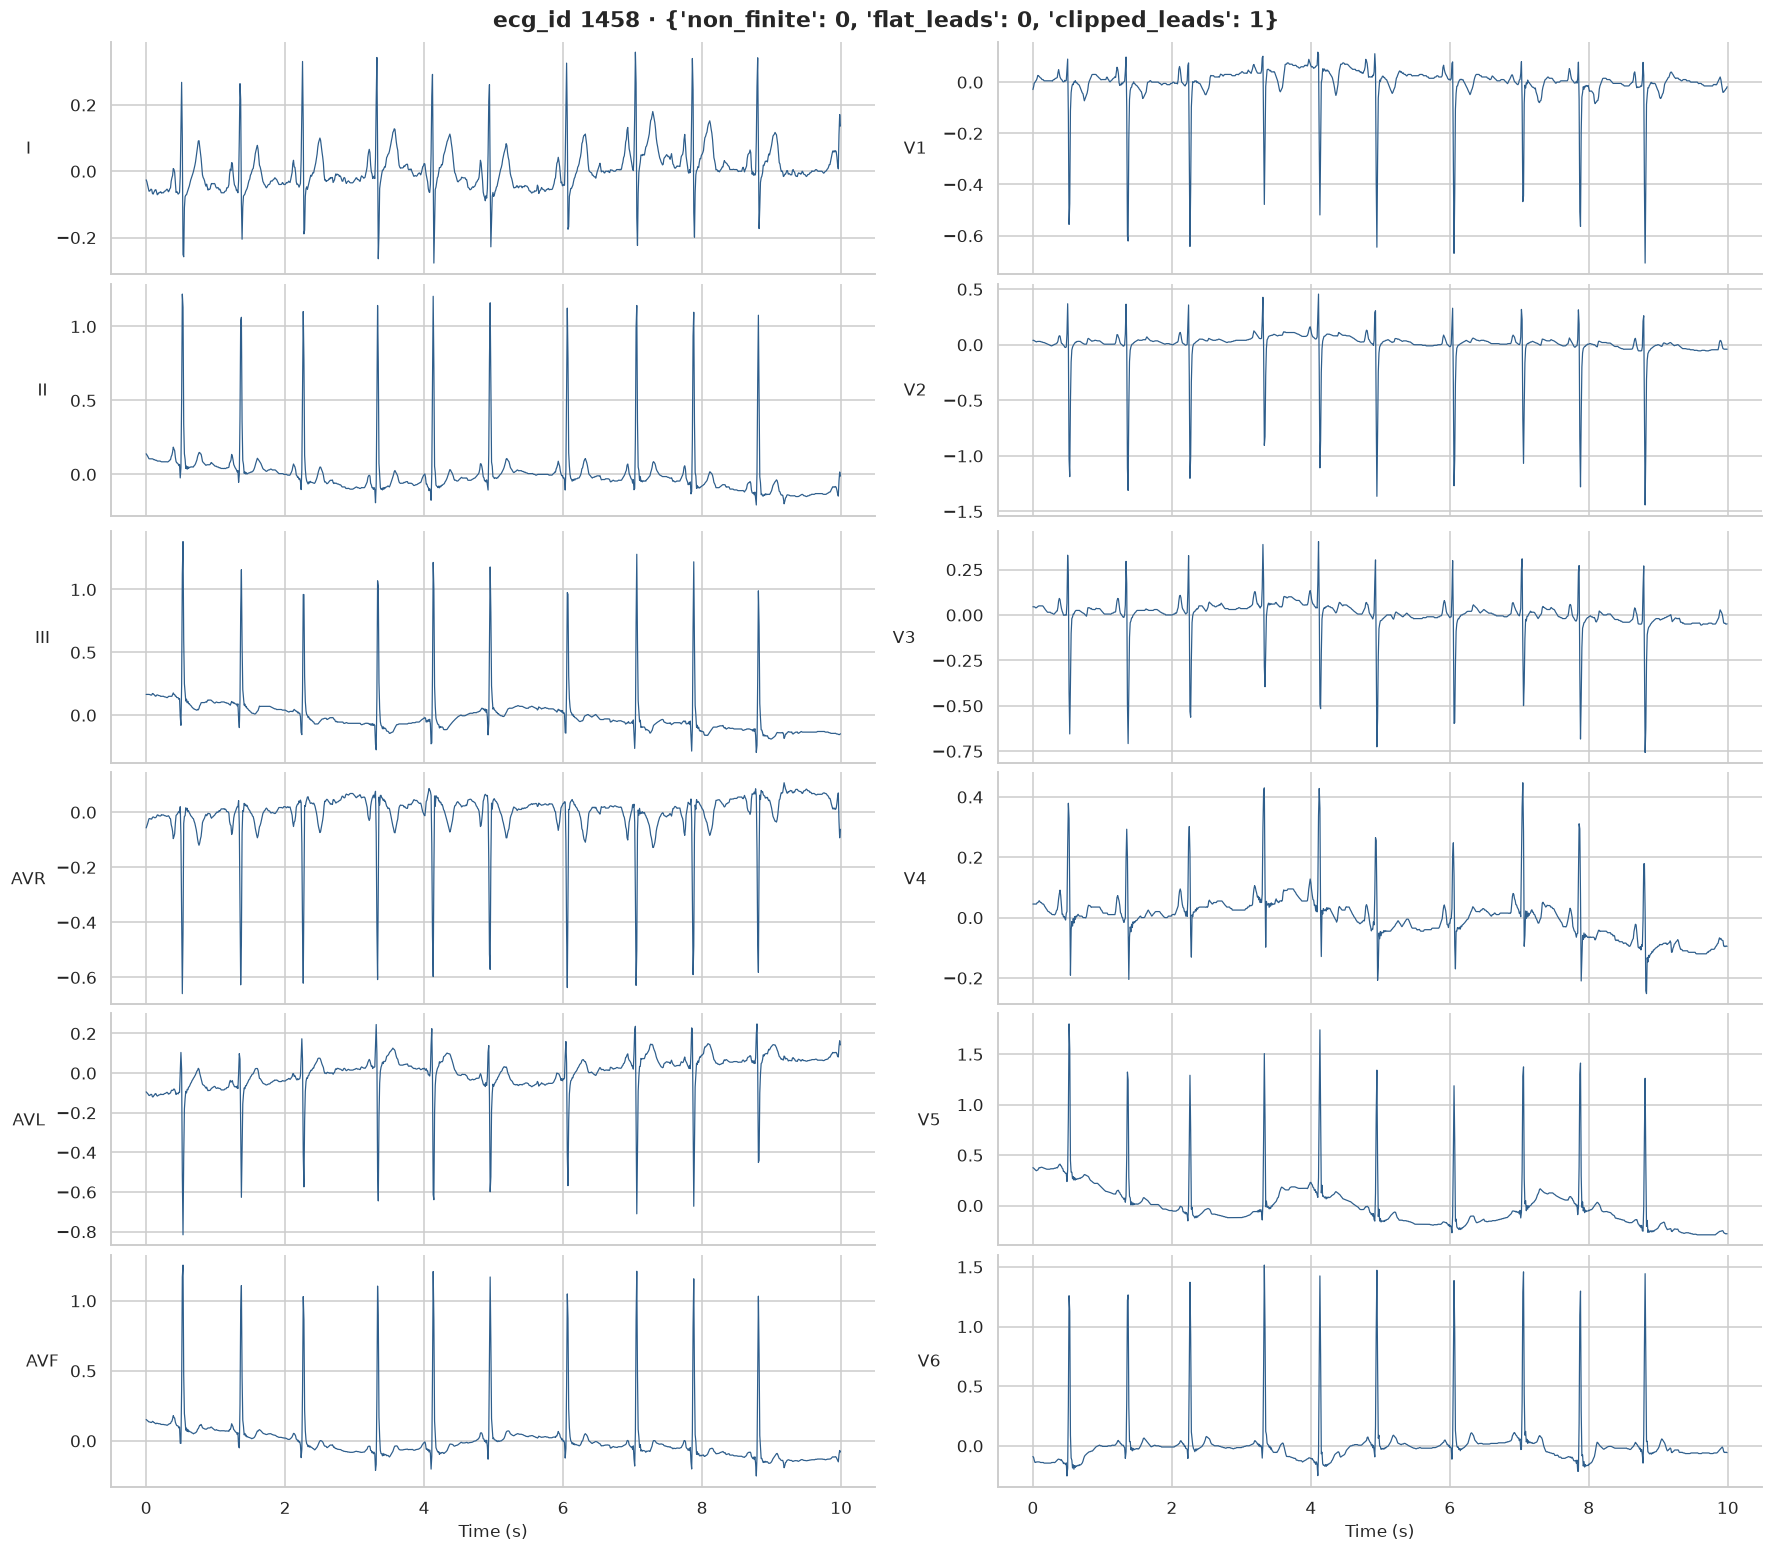

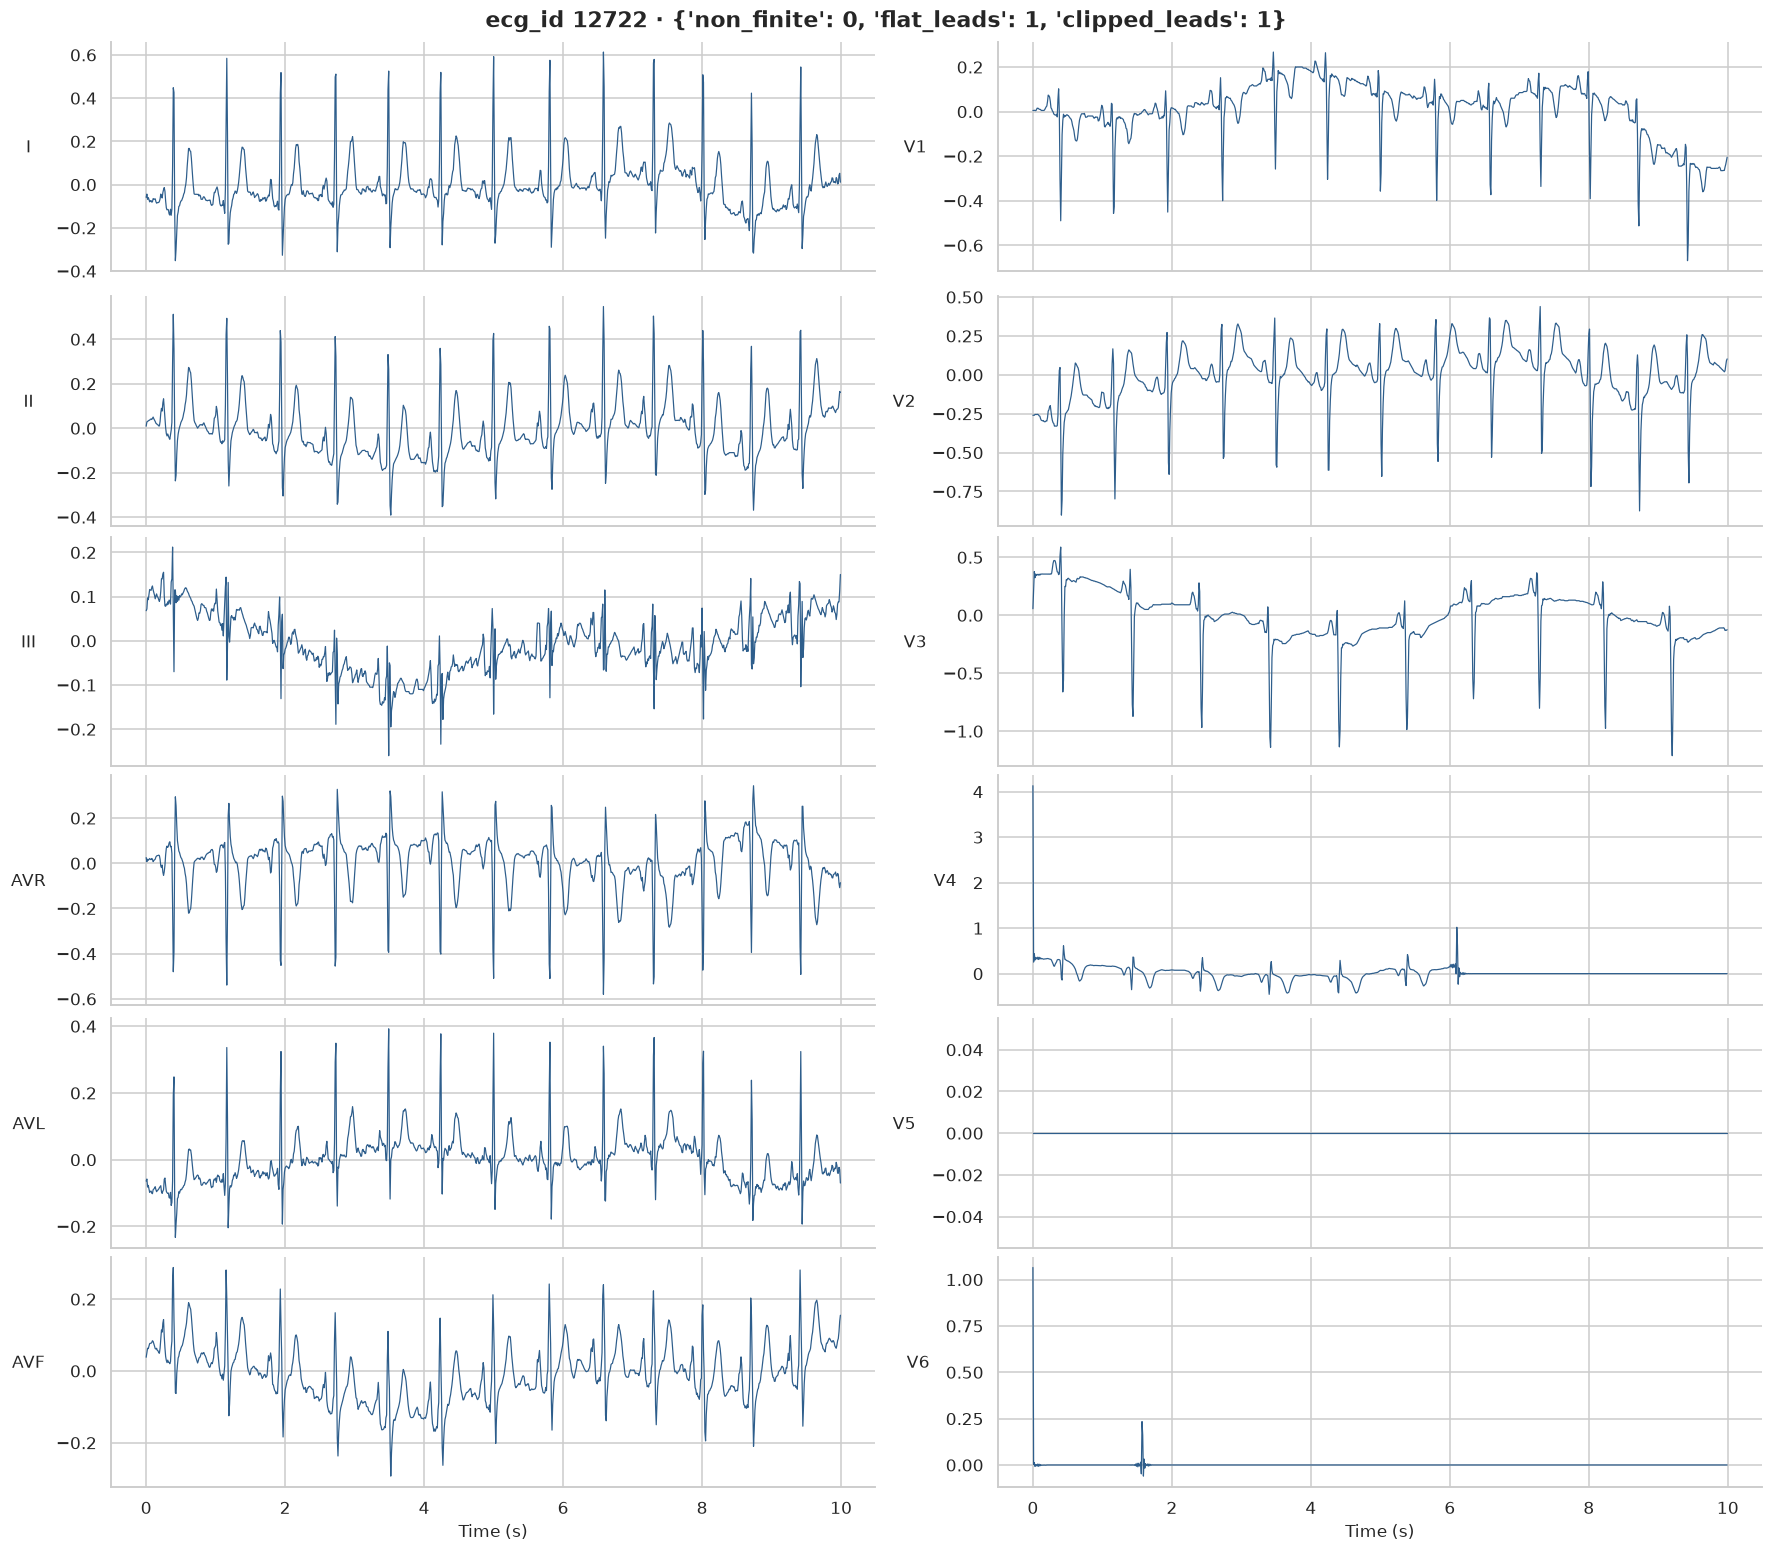

In [13]:
for ecg_id in integrity.index[integrity.gt(0).any(axis=1)]:
    Charts.leads(signal_bank[database.index.get_loc(ecg_id)], SAMPLING_RATE, f"ecg_id {ecg_id} · {integrity.loc[ecg_id].to_dict()}")

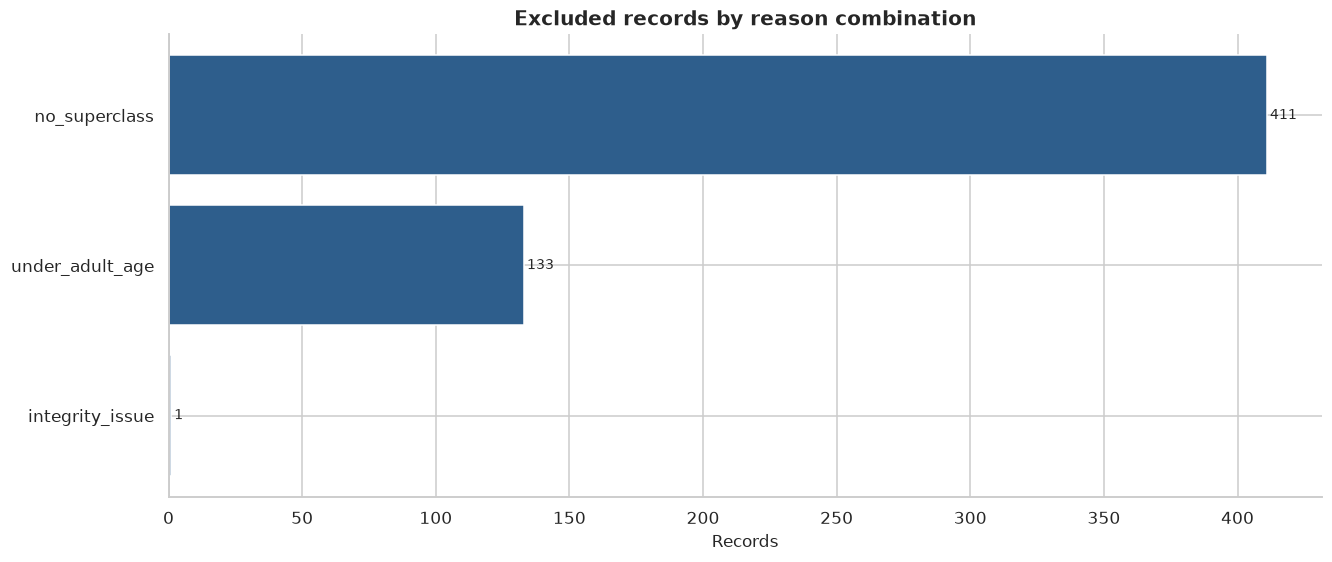

In [14]:
cohort_filter = CohortFilter(database, integrity)
Charts.bar(cohort_filter.reason_combinations(), "Excluded records by reason combination", ylabel="Records", horizontal=True)

In [15]:
cohort_mask = ~cohort_filter.excluded
cohort = database[cohort_mask].copy()
cohort_bank = signal_bank[cohort_mask.to_numpy()]
del signal_bank
print(f"cohort: {len(cohort)} records | {cohort['patient_id'].nunique()} patients | excluded: {(~cohort_mask).sum()}")

cohort: 21254 records | 18499 patients | excluded: 545


In [16]:
label_matrix = LabelMatrix.from_lists(cohort["superclasses"], SUPERCLASSES)
likelihood_matrix = pd.DataFrame(cohort["scp_codes"].apply(hierarchy.superclass_likelihoods).tolist(), index=cohort.index).reindex(columns=list(SUPERCLASSES)).add_prefix("likelihood_")

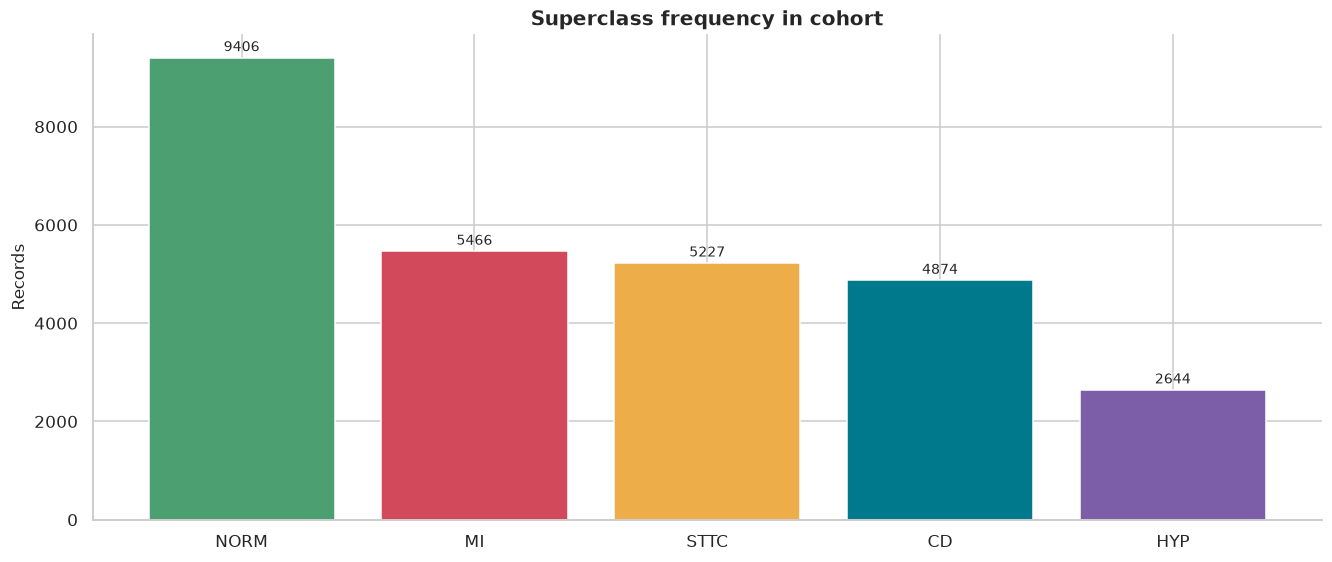

In [17]:
superclass_frequency = label_matrix.sum()
Charts.bar(superclass_frequency, "Superclass frequency in cohort", ylabel="Records", color=PlotTheme.class_colors(superclass_frequency.index))

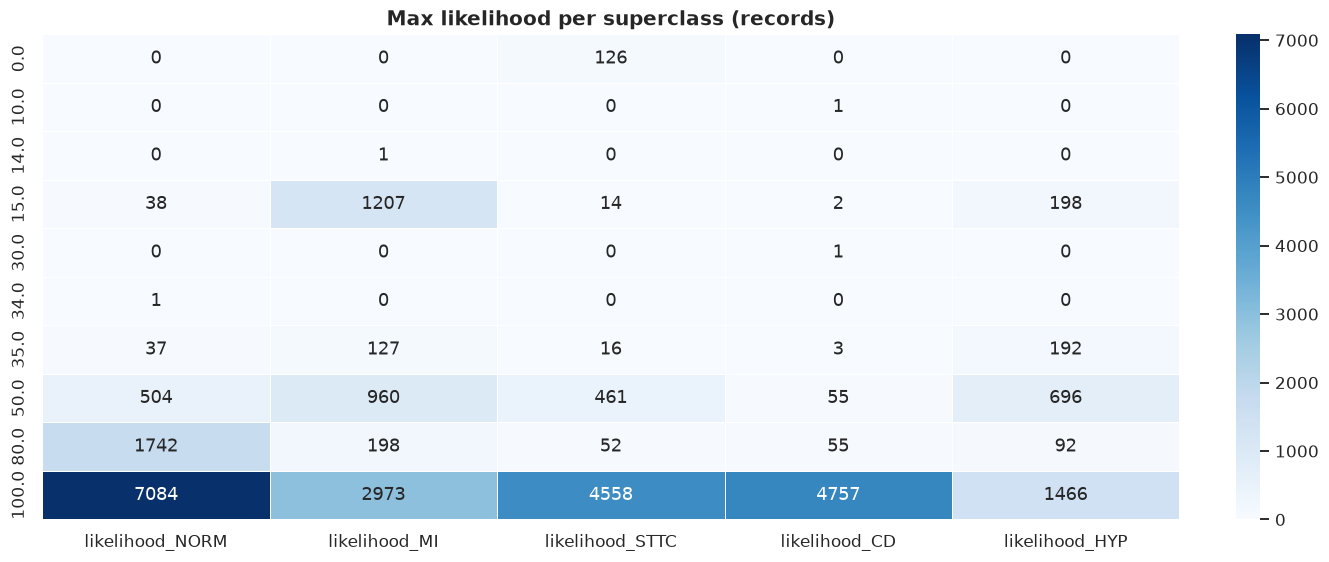

In [18]:
Charts.heatmap(likelihood_matrix.apply(lambda column: column.value_counts()).fillna(0).astype(int), "Max likelihood per superclass (records)", size=BASE_FIGURE_SIZE)

In [19]:
norm_conflict = label_matrix["NORM"].eq(1) & label_matrix[list(CONFLICTING_WITH_NORM)].sum(axis=1).gt(0)
print(f"NORM records with {', '.join(CONFLICTING_WITH_NORM)}: {norm_conflict.sum()}")

NORM records with MI, STTC, HYP: 37


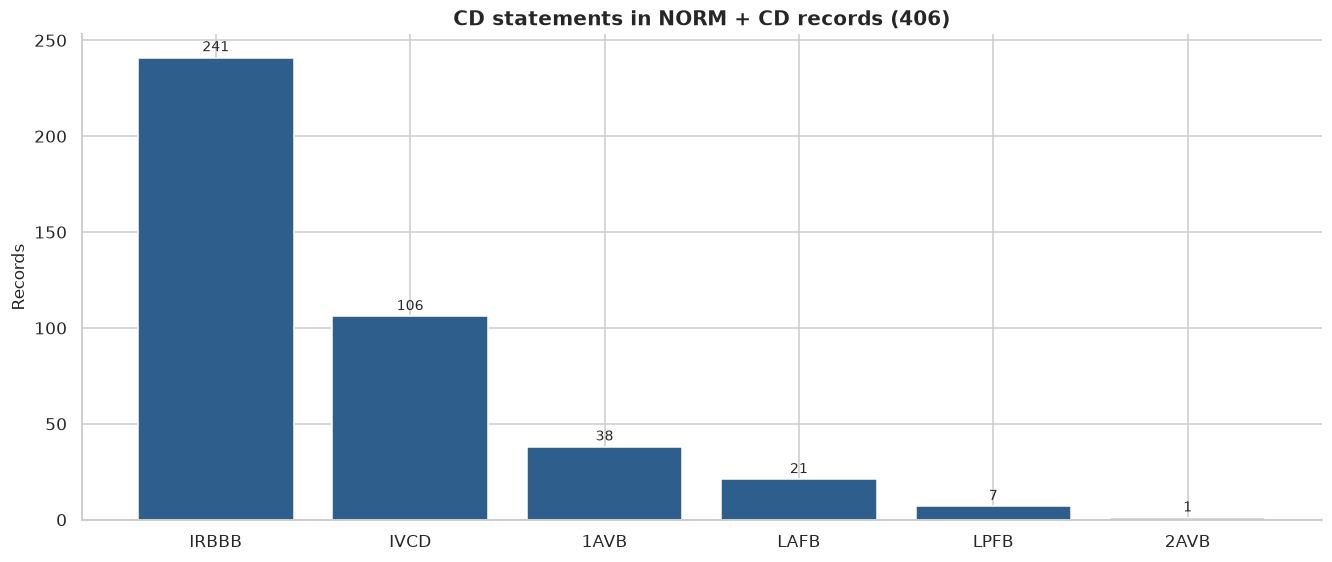

In [20]:
norm_with_cd = label_matrix["NORM"].eq(1) & label_matrix["CD"].eq(1)
cd_statements = pd.Series(Counter(code for codes in cohort.loc[norm_with_cd, "scp_codes"] for code in hierarchy.statements_of(codes, "CD"))).sort_values(ascending=False)
Charts.bar(cd_statements, f"CD statements in NORM + CD records ({norm_with_cd.sum()})", ylabel="Records")

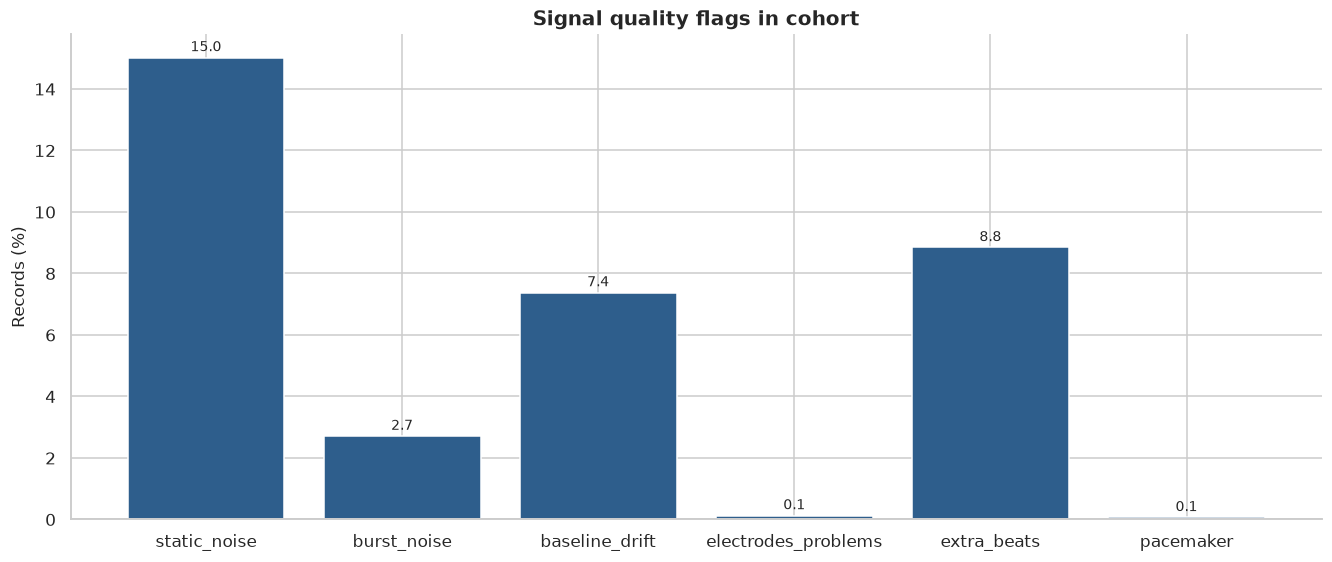

In [21]:
quality_flags = cohort[list(SIGNAL_QUALITY_COLUMNS)].notna().astype(int)
Charts.bar(quality_flags.mean() * 100, "Signal quality flags in cohort", ylabel="Records (%)", value_format="%.1f")

In [22]:
duplicate_finder = NearDuplicateFinder()
duplicate_pairs, nearest_correlation = duplicate_finder.scan(cohort_bank, cohort.index.to_numpy())
print(f"device: {duplicate_finder.device} | pairs above {DUPLICATE_CORRELATION_THRESHOLD}: {len(duplicate_pairs)}")

device: cuda | pairs above 0.99: 0


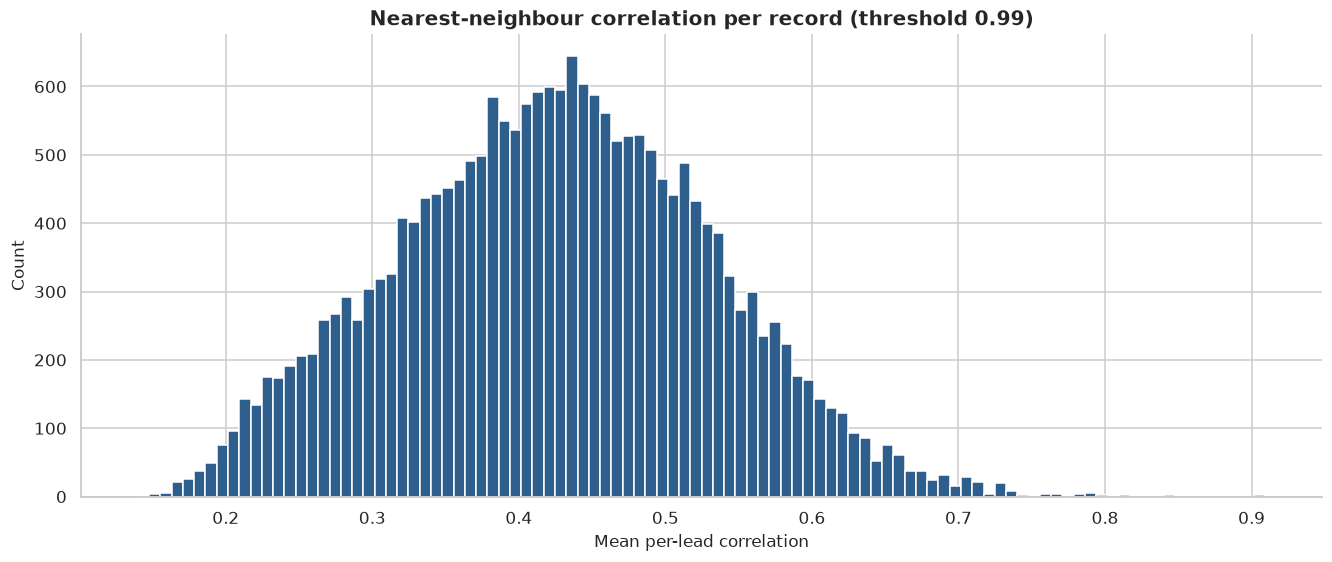

In [23]:
Charts.histogram(nearest_correlation, f"Nearest-neighbour correlation per record (threshold {DUPLICATE_CORRELATION_THRESHOLD})", "Mean per-lead correlation", bins=100)

In [24]:
patient_of = cohort["patient_id"]
duplicate_pairs["same_patient"] = patient_of[duplicate_pairs["ecg_id_a"]].to_numpy() == patient_of[duplicate_pairs["ecg_id_b"]].to_numpy()
duplicate_pairs["same_patient"].value_counts()

Series([], Name: count, dtype: int64)

In [25]:
patient_of = cohort["patient_id"]
duplicate_pairs["same_patient"] = patient_of[duplicate_pairs["ecg_id_a"]].to_numpy() == patient_of[duplicate_pairs["ecg_id_b"]].to_numpy()
duplicate_pairs["same_patient"].value_counts()

Series([], Name: count, dtype: int64)

In [26]:
cross_patient_pairs = duplicate_pairs[~duplicate_pairs["same_patient"]]
patient_union = GroupUnion(patient_of.unique())
patient_union.join(zip(patient_of[cross_patient_pairs["ecg_id_a"]], patient_of[cross_patient_pairs["ecg_id_b"]]))
cohort["group_id"] = patient_union.group_ids(patient_of)
print(f"groups: {cohort['group_id'].nunique()} | patients: {patient_of.nunique()} | largest group: {cohort.groupby('group_id').size().max()} records")

groups: 18499 | patients: 18499 | largest group: 10 records


In [27]:
signal_filter = SignalFilter(SAMPLING_RATE)
example_selector = ExampleSelector(quality_flags, np.random.default_rng(RANDOM_SEED))

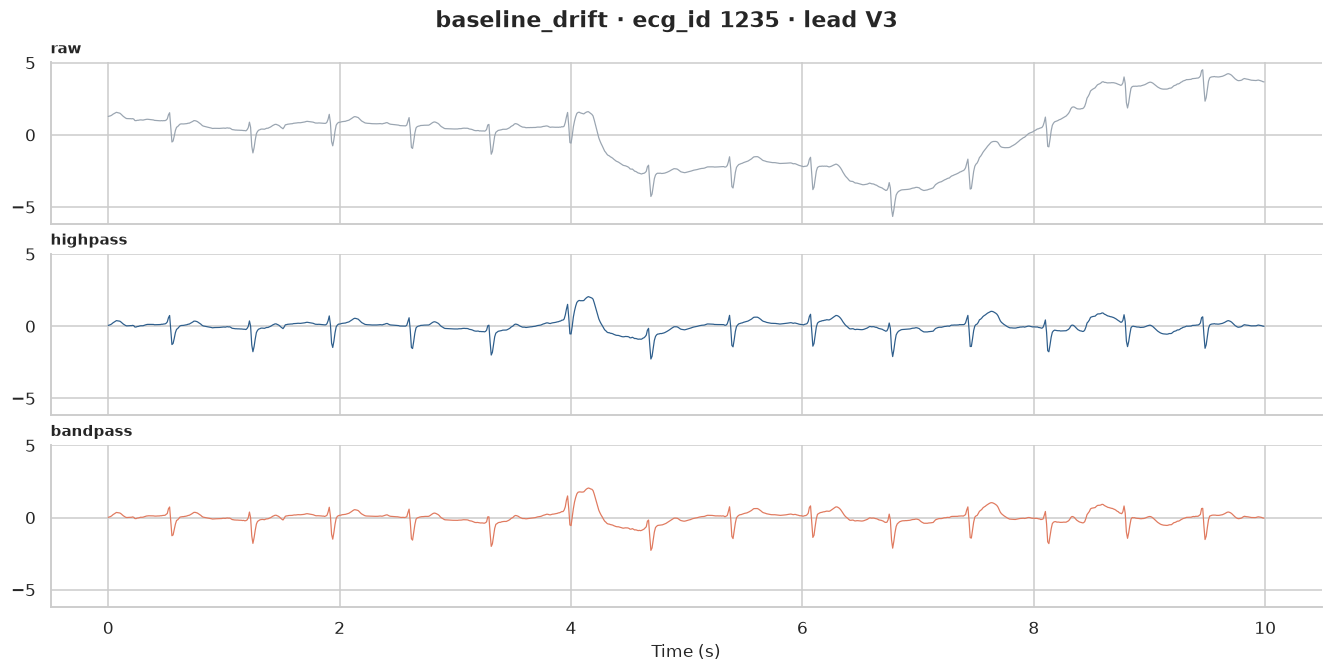

In [28]:
drift_row = example_selector.flagged_row("baseline_drift")
drift_lead = signal_filter.most_affected_lead(cohort_bank[drift_row], "highpass")
Charts.lead_comparison(signal_filter.variants(cohort_bank[drift_row]), SAMPLING_RATE, drift_lead, f"baseline_drift · ecg_id {cohort.index[drift_row]} · lead {LEAD_NAMES[drift_lead]}", FILTER_COLORS)

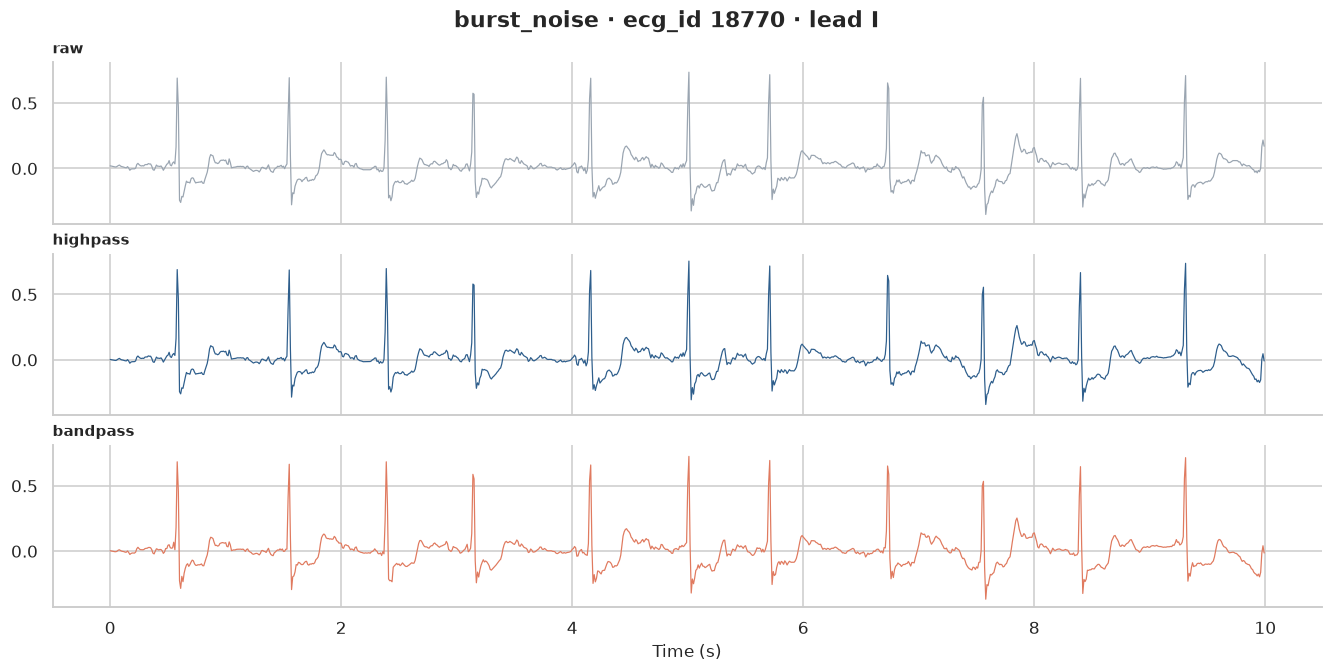

In [29]:
burst_row = example_selector.flagged_row("burst_noise")
burst_lead = signal_filter.most_affected_lead(cohort_bank[burst_row], "bandpass")
Charts.lead_comparison(signal_filter.variants(cohort_bank[burst_row]), SAMPLING_RATE, burst_lead, f"burst_noise · ecg_id {cohort.index[burst_row]} · lead {LEAD_NAMES[burst_lead]}", FILTER_COLORS)

In [30]:
spectrum_batch = cohort_bank[np.sort(example_selector.rng.choice(len(cohort_bank), min(SPECTRUM_SAMPLE_SIZE, len(cohort_bank)), replace=False))]
mean_power = pd.DataFrame({variant: SignalInspector.mean_power(signal_filter.apply(spectrum_batch, variant), SAMPLING_RATE) for variant in FILTER_VARIANTS})

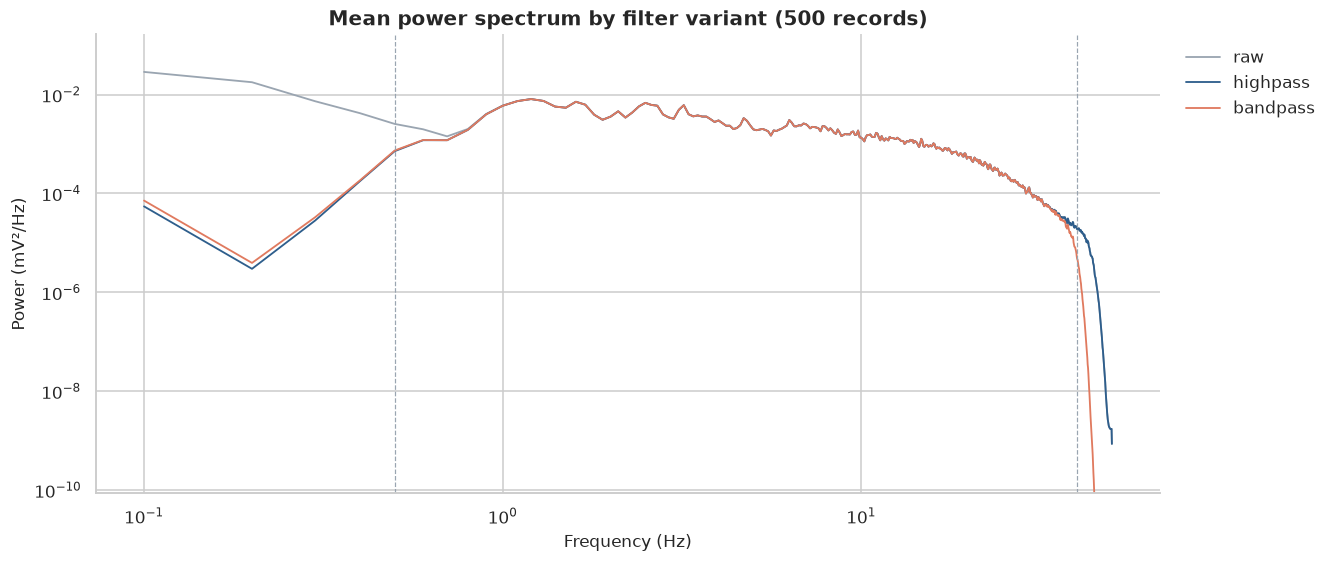

In [31]:
Charts.spectra(mean_power, f"Mean power spectrum by filter variant ({SPECTRUM_SAMPLE_SIZE} records)", FILTER_COLORS, markers=(HIGHPASS_CUTOFF, BANDPASS_CUTOFFS[1]))

In [32]:
records = pd.concat(
    [
        cohort[list(RECORD_IDENTITY_COLUMNS)],
        label_matrix,
        likelihood_matrix,
        norm_conflict.astype(int).rename("norm_conflict"),
        quality_flags.add_prefix("flag_"),
        cohort[list(RECORD_CONTEXT_COLUMNS)]
    ],
    axis=1
)
assert records.index.is_monotonic_increasing and records.index.equals(cohort.index) and len(records) == len(cohort_bank)
records.head()

,patient_id,group_id,age,sex,NORM,MI,STTC,CD,HYP,likelihood_NORM,...,flag_static_noise,flag_burst_noise,flag_baseline_drift,flag_electrodes_problems,flag_extra_beats,flag_pacemaker,device,site,validated_by_human,strat_fold
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,13342,56.0,1,1,0,0,0,0,100.0,...,1,0,0,0,0,0,CS-12 E,0.0,True,3
2,13243.0,11249,19.0,0,1,0,0,0,0,80.0,...,0,0,0,0,0,0,CS-12 E,0.0,True,2
3,20372.0,17281,37.0,1,1,0,0,0,0,100.0,...,0,0,0,0,0,0,CS-12 E,0.0,True,5
4,17014.0,14448,24.0,0,1,0,0,0,0,100.0,...,0,0,1,0,0,0,CS-12 E,0.0,True,3
5,17448.0,14793,19.0,1,1,0,0,0,0,100.0,...,0,0,1,0,0,0,CS-12 E,0.0,True,4


In [33]:
writer = ArtifactWriter(PROCESSED_DATA_DIR)
writer.signals(cohort_bank)
writer.records(records)

In [34]:
preprocessing_report = PreprocessingReport.build(database, cohort_filter, records, duplicate_pairs, cohort_bank)
writer.report(preprocessing_report)
{key: preprocessing_report[key] for key in ("source", "cohort", "label_counts", "norm_conflict_records")}

{'source': {'records': 21799, 'patients': 18869},
 'cohort': {'records': 21254, 'patients': 18499, 'groups': 18499},
 'label_counts': {'NORM': 9406,
  'MI': 5466,
  'STTC': 5227,
  'CD': 4874,
  'HYP': 2644},
 'norm_conflict_records': 37}

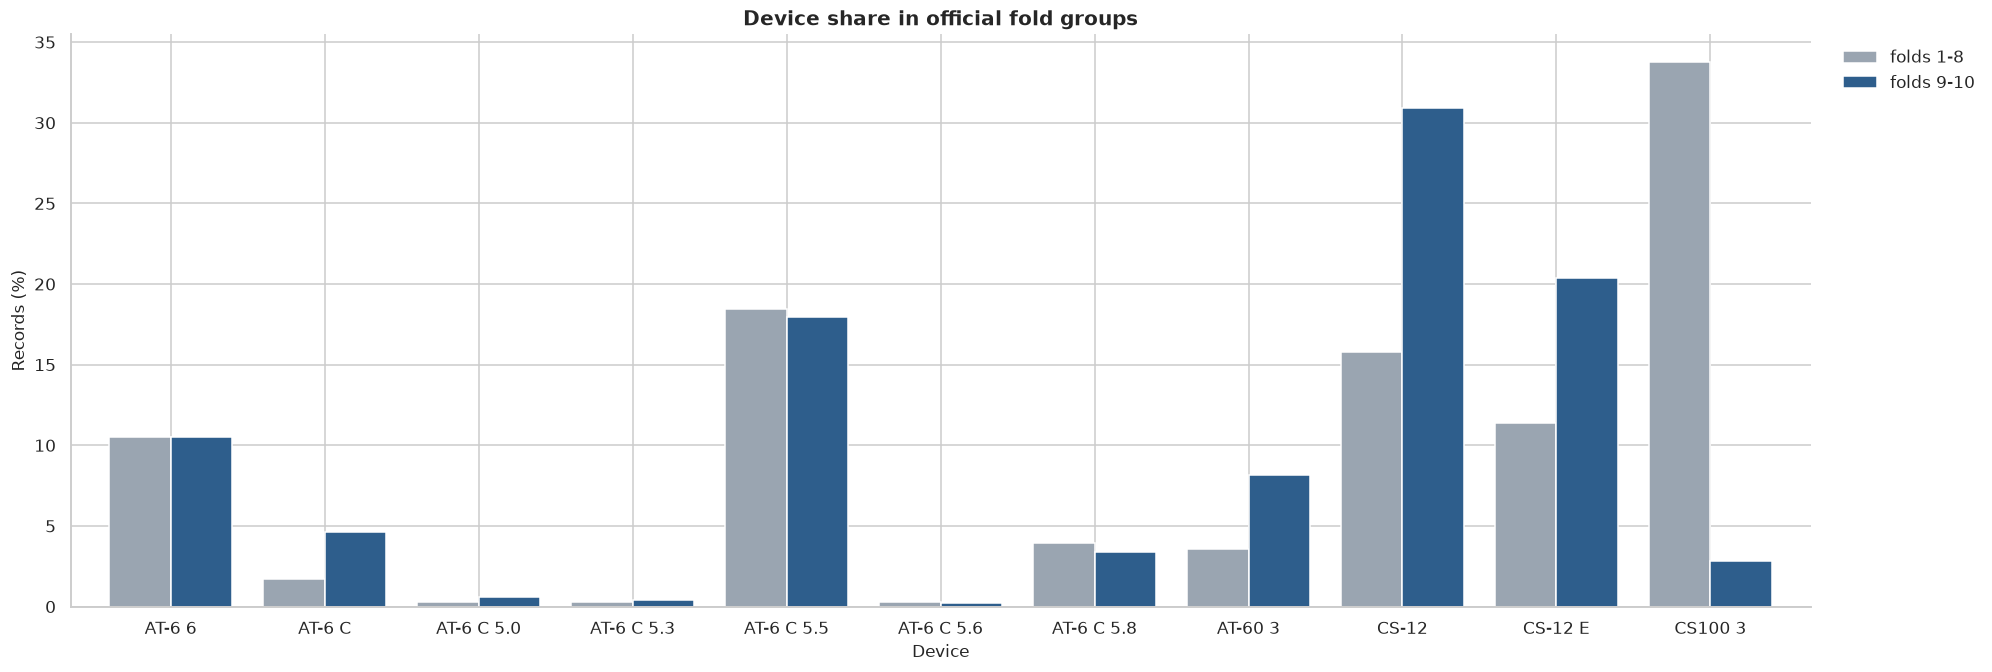

In [35]:
official_fold_group = pd.Series(np.where(records["strat_fold"].isin(OFFICIAL_TEST_FOLDS), OFFICIAL_FOLD_GROUPS[1], OFFICIAL_FOLD_GROUPS[0]), index=records.index)
device_share = pd.crosstab(records["device"], official_fold_group, normalize="columns")[list(OFFICIAL_FOLD_GROUPS)]
Charts.grouped_bar(device_share * 100, "Device share in official fold groups", "Device", "Records (%)", colors=[NEUTRAL_COLOR, PRIMARY_COLOR], size=WIDE_FIGURE_SIZE)

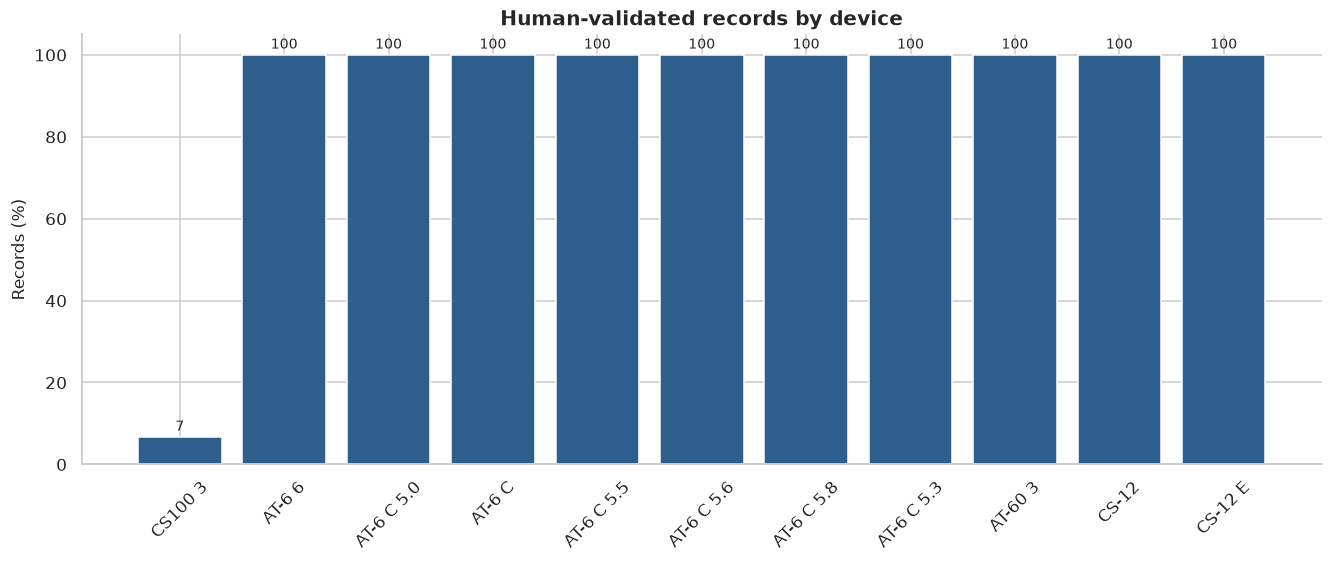

In [36]:
validated_by_device = records.groupby("device")["validated_by_human"].mean().sort_values()
Charts.bar(validated_by_device * 100, "Human-validated records by device", ylabel="Records (%)", value_format="%.0f", rotation=45)

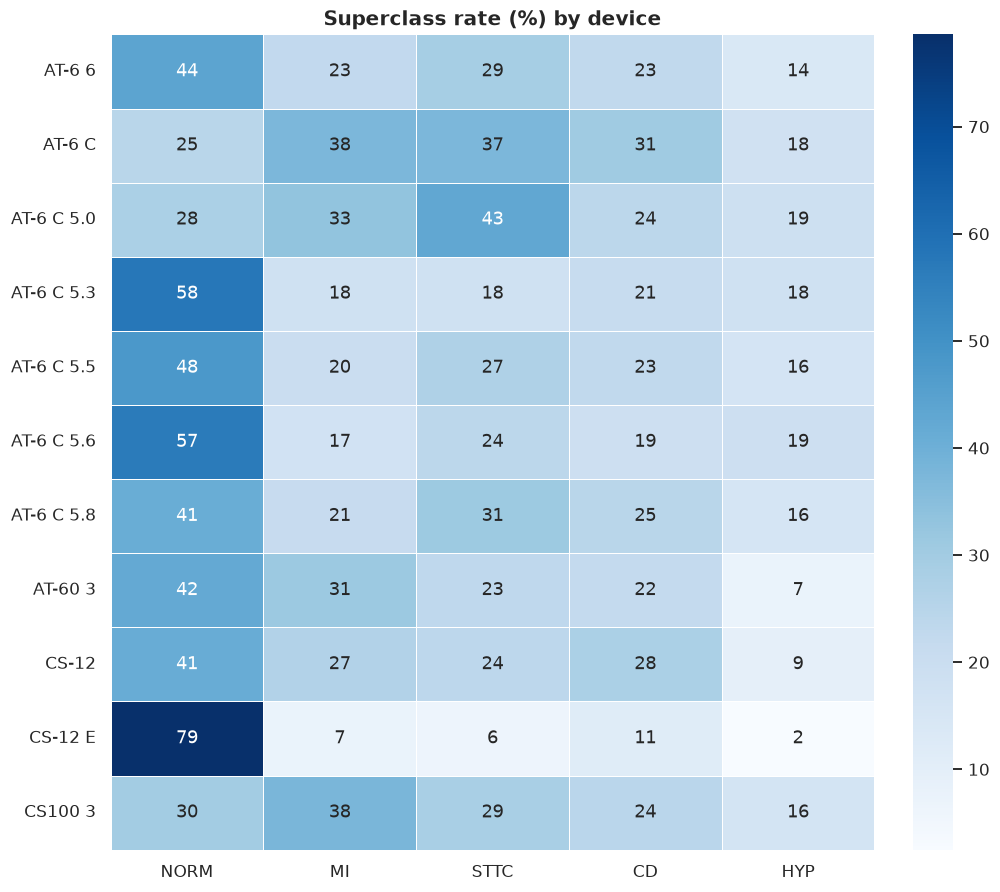

In [37]:
Charts.heatmap(records.groupby("device")[list(SUPERCLASSES)].mean() * 100, "Superclass rate (%) by device", value_format=".0f")

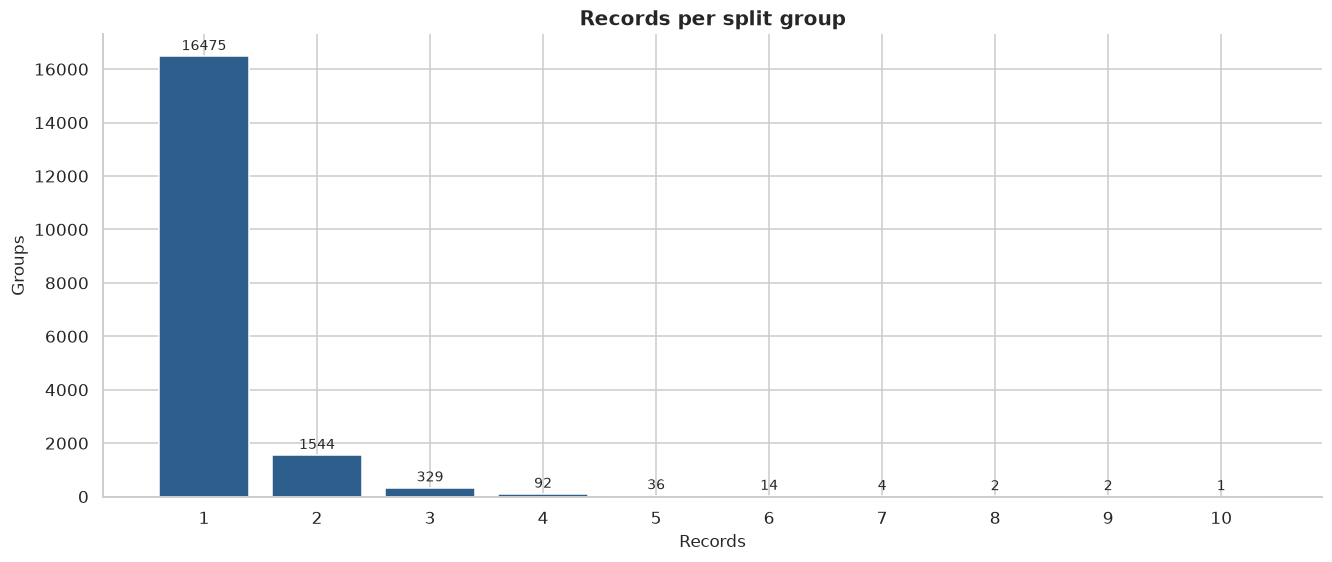

In [38]:
group_sizes = records.groupby("group_id").size()
Charts.bar(group_sizes.value_counts().sort_index(), "Records per split group", xlabel="Records", ylabel="Groups")